In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image
from scipy.fft import dctn
from torchvision.models import (
    ConvNeXt_Tiny_Weights,
    ResNet50_Weights,
    ViT_B_16_Weights,
    convnext_tiny,
    resnet50,
    vit_b_16,
)

from ml_security import ChallengeClient
from ml_security.utils import save_image


In [4]:
client = ChallengeClient.from_env()
challenge_image_id = "challenge_sample_0356"
run_dir = Path("notebook_runs/challenge1_two_stage")
run_dir.mkdir(parents=True, exist_ok=True)

probe_image_path = run_dir / "probe_random.png"
source_image_path = run_dir / "target_class_source.png"
final_attack_path = run_dir / "final_attack.png"

n_steps = 30
epsilon = 0.05
simba_delta = 0.2
square_seed = 17

print("Budget")
print(client.get_budget())
print(f"Challenge image: {challenge_image_id}")
print(f"Source image path: {source_image_path}")
print(f"Final attack path: {final_attack_path}")


Budget
{'query_budget': 10000, 'queries_used': 0, 'queries_remaining': 10000}
Challenge image: challenge_sample_0356
Source image path: notebook_runs/challenge1_two_stage/target_class_source.png
Final attack path: notebook_runs/challenge1_two_stage/final_attack.png


In [5]:
rng = np.random.default_rng(7)
random_probe_image = rng.integers(0, 256, size=(224, 224, 3), dtype=np.uint8)
save_image(random_probe_image, str(probe_image_path))

probe_submission = client.submit_adversarial(str(probe_image_path), image_id=challenge_image_id)
target_class = probe_submission["target_class"]
target_class_name = probe_submission["target_class_name"]

print("Probe submission result")
print(probe_submission)
print(f"Revealed target_class: {target_class}")
print(f"Revealed target_class_name: {target_class_name}")


Probe submission result
{'image_id': 'challenge_sample_0356', 'target_class': 359, 'target_class_name': 'black-footed ferret', 'target_probability': 0.0004, 'queries_used': 0, 'l2_norm': 151.61744689941406, 'linf_norm': 0.9882352948188782, 'previous_best_prob': None, 'improved': True, 'rank': 1}
Revealed target_class: 359
Revealed target_class_name: black-footed ferret


In [9]:
print("Save a real target-class image to this path before running the local attack pipeline:")
print(source_image_path)
print(f"Target class to match: {target_class} ({target_class_name})")


Save a real target-class image to this path before running the local attack pipeline:
notebook_runs/challenge1_two_stage/target_class_source.png
Target class to match: 359 (black-footed ferret)


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /home/cbr4l0k/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100.0%


Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /home/cbr4l0k/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100.0%


Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /home/cbr4l0k/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100.0%


Baseline and attack summary
resnet50
{'predicted_class': 382, 'predicted_probability': 0.339625, 'target_probability': 0.000482, 'simba_final': 0.000482, 'square_final': 0.000568}
vit_b_16
{'predicted_class': 382, 'predicted_probability': 0.447581, 'target_probability': 0.000143, 'simba_final': 0.000143, 'square_final': 0.000154}
convnext_tiny
{'predicted_class': 382, 'predicted_probability': 0.508891, 'target_probability': 0.000222, 'simba_final': 0.000222, 'square_final': 0.000321}
Best result
resnet50 Square Attack 0.0005684513598680496
Saved best adversarial image to notebook_runs/challenge1_two_stage/final_attack.png


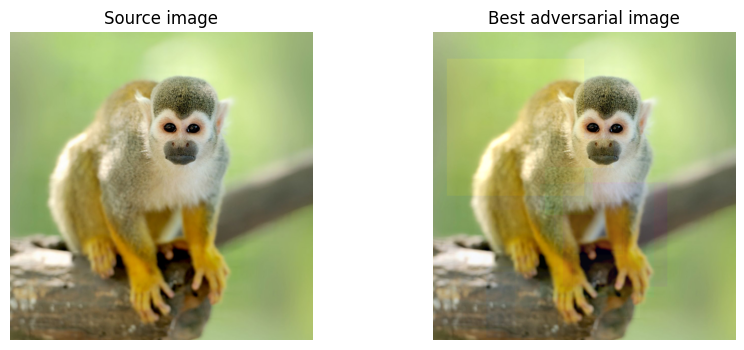

In [10]:
if not source_image_path.exists():
    raise FileNotFoundError(
        f"Expected a real target-class image at {source_image_path}. Save it first, then rerun this cell."
    )


def load_rgb_image(path: Path) -> np.ndarray:
    image = Image.open(path).convert("RGB")
    return np.asarray(image, dtype=np.float32) / 255.0


def to_uint8_image(image: np.ndarray) -> np.ndarray:
    return np.clip(np.rint(image * 255.0), 0, 255).astype(np.uint8)


def load_local_models() -> dict[str, tuple[torch.nn.Module, object]]:
    models = {
        "resnet50": (resnet50(weights=ResNet50_Weights.IMAGENET1K_V2), ResNet50_Weights.IMAGENET1K_V2.transforms()),
        "vit_b_16": (vit_b_16(weights=ViT_B_16_Weights.IMAGENET1K_V1), ViT_B_16_Weights.IMAGENET1K_V1.transforms()),
        "convnext_tiny": (
            convnext_tiny(weights=ConvNeXt_Tiny_Weights.IMAGENET1K_V1),
            ConvNeXt_Tiny_Weights.IMAGENET1K_V1.transforms(),
        ),
    }
    for model, _ in models.values():
        model.eval()
    return models


def build_probability_model(model: torch.nn.Module, transform):
    def preprocess(image_array: np.ndarray) -> torch.Tensor:
        image_uint8 = to_uint8_image(image_array)
        pil_image = Image.fromarray(image_uint8)
        return transform(pil_image).unsqueeze(0)

    def probability_model(x_tensor: torch.Tensor) -> np.ndarray:
        with torch.no_grad():
            probabilities = torch.softmax(model(x_tensor), dim=1)[0]
        return probabilities.detach().cpu().numpy()

    probability_model.preprocess = preprocess
    return probability_model


class SimBADCTAttack:
    def __init__(
        self,
        model,
        x_init: np.ndarray,
        target_class: int,
        n_steps: int,
        epsilon: float,
        delta: float = 0.2,
        seed: int = 0,
    ) -> None:
        self.model = model
        self.x_init = x_init.astype(np.float32)
        self.target_class = int(target_class)
        self.n_steps = int(n_steps)
        self.epsilon = float(epsilon)
        self.delta = float(delta)
        self.rng = np.random.default_rng(seed)
        self.height, self.width, self.channels = self.x_init.shape
        self.basis_order = self.rng.permutation(self.height * self.width)

    def _clip(self, image: np.ndarray) -> np.ndarray:
        lower = np.clip(self.x_init - self.epsilon, 0.0, 1.0)
        upper = np.clip(self.x_init + self.epsilon, 0.0, 1.0)
        return np.clip(image, lower, upper).astype(np.float32)

    def _target_probability(self, image: np.ndarray) -> float:
        x_tensor = self.model.preprocess(image)
        probabilities = self.model(x_tensor)
        return float(probabilities[self.target_class])

    def _direction(self, basis_index: int) -> np.ndarray:
        y, x = divmod(int(basis_index), self.width)
        seed = np.zeros((self.height, self.width), dtype=np.float32)
        seed[y, x] = 1.0
        basis_2d = dctn(seed, norm="ortho")
        basis_2d /= np.linalg.norm(basis_2d) + 1e-12
        return np.repeat(basis_2d[:, :, None], self.channels, axis=2).astype(np.float32) * self.delta

    def run(self) -> tuple[np.ndarray, list[float]]:
        x_adv = self.x_init.copy()
        p_current = self._target_probability(x_adv)
        p_trajectory: list[float] = []

        for step in range(self.n_steps):
            basis_index = self.basis_order[step % len(self.basis_order)]
            direction = self._direction(basis_index)

            accepted = False
            for sign in (1.0, -1.0):
                x_new = self._clip(x_adv + sign * direction)
                p_new = self._target_probability(x_new)
                if p_new > p_current:
                    x_adv = x_new
                    p_current = p_new
                    p_trajectory.append(p_current)
                    accepted = True
                    break

            if not accepted:
                continue

        return x_adv, p_trajectory


class SquareAttack:
    def __init__(
        self,
        model,
        x_init: np.ndarray,
        target_class: int,
        n_steps: int,
        epsilon: float,
        seed: int = 0,
    ) -> None:
        self.model = model
        self.x_init = x_init.astype(np.float32)
        self.target_class = int(target_class)
        self.n_steps = int(n_steps)
        self.epsilon = float(epsilon)
        self.rng = np.random.default_rng(seed)
        self.height, self.width, self.channels = self.x_init.shape
        self.image_side = min(self.height, self.width)

    def _clip(self, image: np.ndarray) -> np.ndarray:
        lower = np.clip(self.x_init - self.epsilon, 0.0, 1.0)
        upper = np.clip(self.x_init + self.epsilon, 0.0, 1.0)
        return np.clip(image, lower, upper).astype(np.float32)

    def _target_probability(self, image: np.ndarray) -> float:
        x_tensor = self.model.preprocess(image)
        probabilities = self.model(x_tensor)
        return float(probabilities[self.target_class])

    def _patch_size(self, step: int) -> int:
        if self.n_steps <= 1:
            fraction = 0.05
        else:
            progress = step / (self.n_steps - 1)
            fraction = 0.5 + (0.05 - 0.5) * progress
        return max(1, int(round(self.image_side * fraction)))

    def run(self) -> tuple[np.ndarray, list[float]]:
        x_adv = self.x_init.copy()
        p_current = self._target_probability(x_adv)
        p_trajectory: list[float] = []

        for step in range(self.n_steps):
            patch_size = self._patch_size(step)
            max_y = max(1, self.height - patch_size + 1)
            max_x = max(1, self.width - patch_size + 1)
            y0 = int(self.rng.integers(0, max_y))
            x0 = int(self.rng.integers(0, max_x))
            patch_value = self.rng.uniform(-self.epsilon, self.epsilon, size=(1, 1, self.channels)).astype(np.float32)

            proposal = x_adv.copy()
            proposal[y0 : y0 + patch_size, x0 : x0 + patch_size, :] += patch_value
            x_new = self._clip(proposal)
            p_new = self._target_probability(x_new)

            if p_new > p_current:
                x_adv = x_new
                p_current = p_new
                p_trajectory.append(p_current)

        return x_adv, p_trajectory


def run_baseline(probability_model, image_array: np.ndarray, target_class: int) -> dict[str, float | int]:
    probabilities = probability_model(probability_model.preprocess(image_array))
    predicted_class = int(np.argmax(probabilities))
    predicted_probability = float(probabilities[predicted_class])
    target_probability = float(probabilities[int(target_class)])
    return {
        "predicted_class": predicted_class,
        "predicted_probability": predicted_probability,
        "target_probability": target_probability,
    }


def run_adversarial_pipeline(
    image_array: np.ndarray,
    target_class: int,
    n_steps: int,
    epsilon: float,
) -> dict[str, dict[str, object]]:
    results: dict[str, dict[str, object]] = {}

    for model_index, (model_name, (model, transform)) in enumerate(models.items()):
        probability_model = build_probability_model(model, transform)
        baseline = run_baseline(probability_model, image_array, target_class)

        simba = SimBADCTAttack(
            model=probability_model,
            x_init=image_array,
            target_class=target_class,
            n_steps=n_steps,
            epsilon=epsilon,
            delta=simba_delta,
            seed=100 + model_index,
        )
        simba_x_adv, simba_trajectory = simba.run()

        square = SquareAttack(
            model=probability_model,
            x_init=image_array,
            target_class=target_class,
            n_steps=n_steps,
            epsilon=epsilon,
            seed=square_seed + model_index,
        )
        square_x_adv, square_trajectory = square.run()

        results[model_name] = {
            "baseline": baseline,
            "SimBA-DCT": {
                "x_adv": simba_x_adv,
                "p_trajectory": simba_trajectory,
                "final_target_probability": simba_trajectory[-1] if simba_trajectory else baseline["target_probability"],
            },
            "Square Attack": {
                "x_adv": square_x_adv,
                "p_trajectory": square_trajectory,
                "final_target_probability": square_trajectory[-1] if square_trajectory else baseline["target_probability"],
            },
        }

    return results


def select_best_result(results: dict[str, dict[str, object]]) -> dict[str, object]:
    best_result: dict[str, object] | None = None

    for model_name, model_results in results.items():
        for attack_name in ("SimBA-DCT", "Square Attack"):
            attack_result = model_results[attack_name]
            candidate = {
                "model_name": model_name,
                "attack_name": attack_name,
                "final_target_probability": float(attack_result["final_target_probability"]),
                "x_adv": attack_result["x_adv"],
                "p_trajectory": attack_result["p_trajectory"],
            }
            if best_result is None or candidate["final_target_probability"] > best_result["final_target_probability"]:
                best_result = candidate

    if best_result is None:
        raise RuntimeError("No attack results were produced.")

    return best_result


source_image = load_rgb_image(source_image_path)
models = load_local_models()
attack_results = run_adversarial_pipeline(
    image_array=source_image,
    target_class=target_class,
    n_steps=n_steps,
    epsilon=epsilon,
)
best_result = select_best_result(attack_results)
best_image_uint8 = to_uint8_image(best_result["x_adv"])
save_image(best_image_uint8, str(final_attack_path))

print("Baseline and attack summary")
for model_name, model_results in attack_results.items():
    baseline = model_results["baseline"]
    print(model_name)
    print({
        "predicted_class": baseline["predicted_class"],
        "predicted_probability": round(baseline["predicted_probability"], 6),
        "target_probability": round(baseline["target_probability"], 6),
        "simba_final": round(model_results["SimBA-DCT"]["final_target_probability"], 6),
        "square_final": round(model_results["Square Attack"]["final_target_probability"], 6),
    })

print("Best result")
print(best_result["model_name"], best_result["attack_name"], best_result["final_target_probability"])
print(f"Saved best adversarial image to {final_attack_path}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(to_uint8_image(source_image))
axes[0].set_title("Source image")
axes[0].axis("off")
axes[1].imshow(best_image_uint8)
axes[1].set_title("Best adversarial image")
axes[1].axis("off")
plt.show()


In [12]:
final_submission = client.submit_adversarial(str(final_attack_path), image_id=challenge_image_id)
final_submission


{'image_id': 'challenge_sample_0356',
 'target_class': 359,
 'target_class_name': 'black-footed ferret',
 'target_probability': 0.0005,
 'queries_used': 0,
 'l2_norm': 111.31590270996094,
 'linf_norm': 0.9686274528503418,
 'previous_best_prob': 0.0005,
 'improved': False,
 'rank': 1}

Well... This didn't work. But at least there's something relevant to acnowledge: The target probability from our method at least matches the one on the online model, whith a huge asterisc.

# \* `0.0005` is basically zero... so not so good anyways, wrong intuition.

In [13]:
client.get_budget()

{'query_budget': 10000, 'queries_used': 0, 'queries_remaining': 10000}